# Experimento 08 — Análise exploratória de features

**Escopo:** apenas os nove endereços sinalizados no teste de 15/01/2026 (limiar congelado 0,85). **Não é** avaliação representativa de todos os 20.214 endereços e **não** autoriza treinar/otimizar usando o próprio teste.

Fonte: CSV `sinalizados_teste_2026.csv` da pasta `results/` do projeto. A cópia abaixo contém somente as colunas necessárias à análise.

**Cautela:** três rótulos de não mixers são provisórios e três endereços não foram classificados. Não se calcula precisão real com classes desconhecidas.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from io import StringIO
DATA = 'endereco,score,n_tx,value_entropy,fee_entropy,internal_value_entropy,call_count_mean,referencia\n0x12d66f87a04a9e220743712ce6d9bb1b5616b8fc,1.0,74,0.9466474387740497,6.010062993978093,0.9466474387740497,38.4054054054054,tornado_0.1\n0x47ce0c6ed5b0ce3d3a51fdb1c52dc66a7c3c2936,1.0,171,0.7311867136980617,6.836659076375639,0.7311867136980617,40.578947368421055,tornado_1\n0x7251febeabb01ec9de53ece7a96f1c951f886dd2,1.0,83,0.5371772188950283,6.2063647325517435,0.9309768675126928,36.674698795180724,indeterminado\n0x910cbd523d972eb0a6f4cae4618ad62622b39dbf,1.0,43,0.693127415328288,5.333241498888144,0.693127415328288,41.04651162790697,tornado_10\n0x5182fede730b31a9cf7f49c5781214b4a99f2370,0.99,16,0.6685644431995964,3.875,0.6685644431995964,23.625,indeterminado\n0x57bedd7eb4c3118669f4f33a3cae4d4b554f24b7,0.98,66,1.0333384868430027,3.6827063324024683,1.082506858022344,25.0,bridge_preliminar\n0x80226fc0ee2b096224eeac085bb9a8cba1146f7d,0.98,119,0.7767076603548722,6.090695204722137,0.896018972858771,22.57983193277311,indeterminado\n0x2f848984984d6c3c036174ce627703edaf780479,0.91,15,0.7219280948873623,3.906890595608519,0.7219280948873623,600.8,batch_minter_preliminar\n0x27428dd2d3dd32a4d7f7c497eaaa23130d894911,0.86,16,0.9886994082884974,3.875,1.186278124459133,31.0,relayer_preliminar\n'
df=pd.read_csv(StringIO(DATA))
df["grupo"]=np.where(df.referencia.str.startswith("tornado"),"Tornado confirmado","Candidato adicional")
df

,endereco,score,n_tx,value_entropy,fee_entropy,internal_value_entropy,call_count_mean,referencia,grupo
0,0x12d66f87a04a9e220743712ce6d9bb1b5616b8fc,1.00,74,0.946647,6.010063,0.946647,38.405405,tornado_0.1,Tornado confirmado
1,0x47ce0c6ed5b0ce3d3a51fdb1c52dc66a7c3c2936,1.00,171,0.731187,6.836659,0.731187,40.578947,tornado_1,Tornado confirmado
2,0x7251febeabb01ec9de53ece7a96f1c951f886dd2,1.00,83,0.537177,6.206365,0.930977,36.674699,indeterminado,Candidato adicional
3,0x910cbd523d972eb0a6f4cae4618ad62622b39dbf,1.00,43,0.693127,5.333241,0.693127,41.046512,tornado_10,Tornado confirmado
4,0x5182fede730b31a9cf7f49c5781214b4a99f2370,0.99,16,0.668564,3.875000,0.668564,23.625000,indeterminado,Candidato adicional
5,0x57bedd7eb4c3118669f4f33a3cae4d4b554f24b7,0.98,66,1.033338,3.682706,1.082507,25.000000,bridge_preliminar,Candidato adicional
6,0x80226fc0ee2b096224eeac085bb9a8cba1146f7d,0.98,119,0.776708,6.090695,0.896019,22.579832,indeterminado,Candidato adicional
7,0x2f848984984d6c3c036174ce627703edaf780479,0.91,15,0.721928,3.906891,0.721928,600.800000,batch_minter_preliminar,Candidato adicional
8,0x27428dd2d3dd32a4d7f7c497eaaa23130d894911,0.86,16,0.988699,3.875000,1.186278,31.000000,relayer_preliminar,Candidato adicional


In [2]:
cols=["value_entropy","fee_entropy","internal_value_entropy","call_count_mean"]
print(df.groupby("grupo")[cols].agg(["median","min","max"]).round(3).to_string())

                    value_entropy               fee_entropy               internal_value_entropy               call_count_mean                 
                           median    min    max      median    min    max                 median    min    max          median     min      max
grupo                                                                                                                                          
Candidato adicional         0.749  0.537  1.033       3.891  3.683  6.206                  0.913  0.669  1.186          28.000  22.580  600.800
Tornado confirmado          0.731  0.693  0.947       6.010  5.333  6.837                  0.731  0.693  0.947          40.579  38.405   41.047


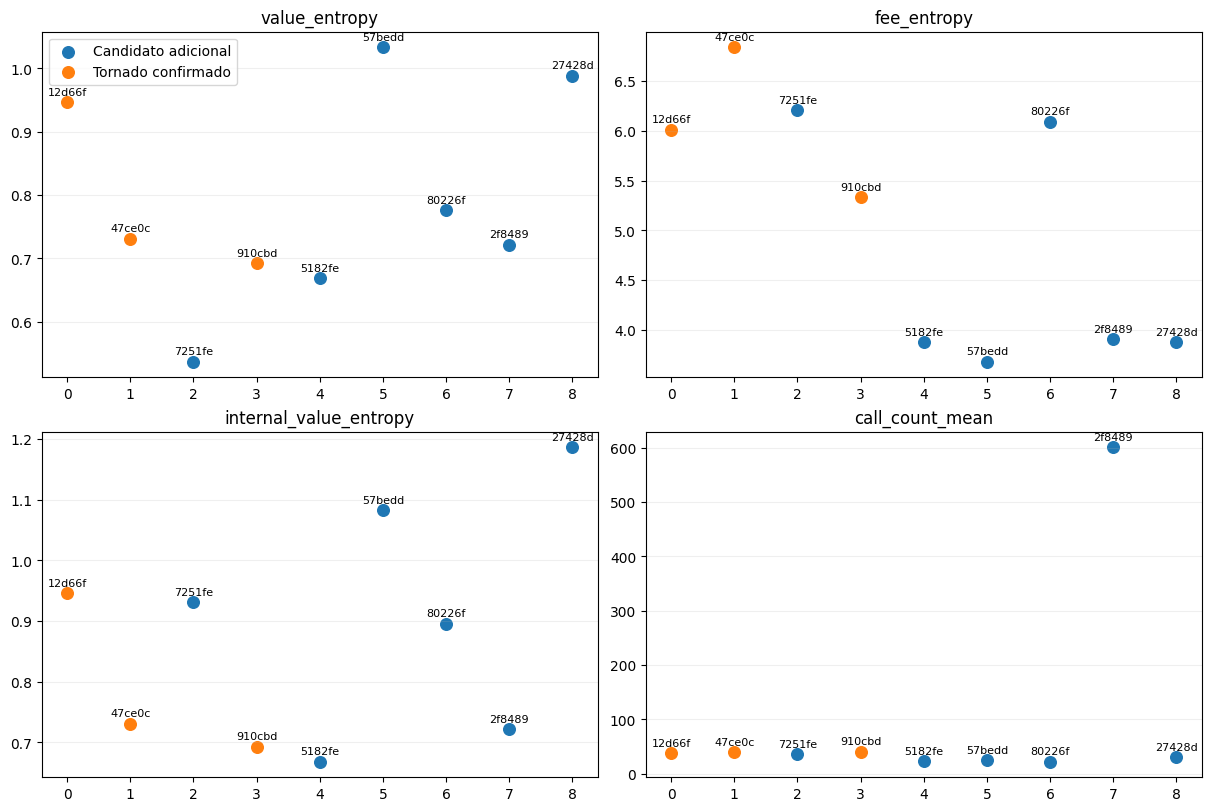

In [3]:
fig, axs=plt.subplots(2,2,figsize=(12,8),layout="constrained")
for ax,feat in zip(axs.ravel(),cols):
    for grp,g in df.groupby("grupo"):
        ax.scatter(g.index,g[feat],label=grp,s=70)
    for idx,row in df.iterrows():
        ax.annotate(row.endereco[2:8],(idx,row[feat]),xytext=(0,5),textcoords="offset points",fontsize=8,ha="center")
    ax.set_title(feat);ax.grid(axis="y",alpha=.2)
axs[0,0].legend()
plt.show()

## O que é possível concluir?
- Há sobreposição de valores das quatro features entre Tornado conhecidos e candidatos adicionais.
- O candidato `0x2f848...` possui `call_count_mean=600,8`, um valor extremo, embora a importância global dessa feature seja alta no modelo original.
- O score não mede a distância a uma faixa simples de cada atributo; a Random Forest usa decisões combinadas.

## O que **não** podemos concluir?
- Que um candidato é definitivamente não mixer apenas porque o nome de seu contrato é bridge, relayer ou minter.
- Que alterar as features ou treinar com esses nove endereços produziria validação externa independente.
- Que esses nove casos representam o perfil dos 20.214 endereços.

## Próximo experimento controlado
Usar dados de treino e validação anteriores ao teste, com endereços agrupados por contrato para reduzir vazamento. Reavaliar alterações em período ainda não utilizado e rótulos revisados.